In this notebook I shall load the training data and perform some preliminery investigations to make some understanding of the provided dataset

First of all I call the necessary python libraries

In [20]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
import seaborn as sns
from src.data_preprocessing import sum_ticket

## Data Loading and basic operations

Now I we load the training dataset as a panda dataframe and explore it

In [2]:
# Loading the data in Panda dataframe
raw_training_data = pd.read_csv('~/Desktop/Titanic_Survival/data/Titanic_train.csv')

# Number of valid entries in the data
print(len(raw_training_data)) 

# Column headings of the loaded dataset
print(raw_training_data.columns)

# Checking dtypes of each column
print(raw_training_data.dtypes)

891
Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object


We find three different types of features in our dataset:

1) int64: PassengerId, Survived, Pclass, SibSp, Parch

2) float64: Age, Fare

3) object: Name, Sex, Cabin, Embarked

Among these "PassengerID" is just an identification id and "Survived" is the target variable. It represents whether the passenger survived or not

Now in the training data I shall check which rows of "Survived" column contains "NaN", "None", " " etc and drop those rows from the entire dataset since these entires can not be used for training our model

In [3]:
noise = raw_training_data['Survived'].isna() | (raw_training_data['Survived'] == '')

# Get the matching rows
missing_rows = raw_training_data[noise]
print(missing_rows)

train_data_cleaned = raw_training_data[~noise]
train_target = train_data_cleaned[['Survived']].astype(np.float32)

# No of entries remain same since all rows of "Survived" contain a valid entry
print(len(train_data_cleaned)) 

Empty DataFrame
Columns: [PassengerId, Survived, Pclass, Name, Sex, Age, SibSp, Parch, Ticket, Fare, Cabin, Embarked]
Index: []
891


## Data Visualization

Now we shall try to visualize the data to gain some understanding of it. 

We start with investigating what percentage of passengers survived vs what percentage didn't

<Axes: xlabel='Survived'>

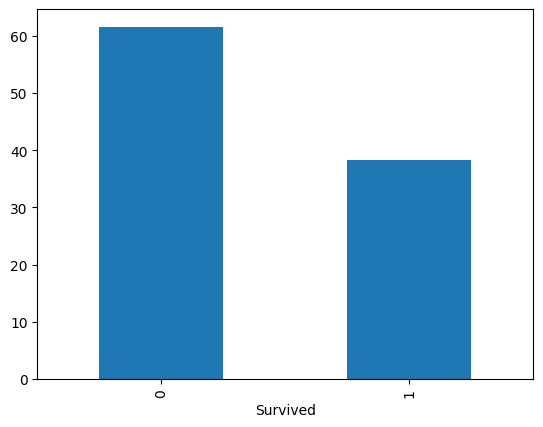

In [4]:
(train_data_cleaned['Survived'].value_counts(normalize=True) * 100.0).plot(kind='bar')

First of all I choose to investigate the dependencies with "Categorical" features: "Pclass", "Sex", "SibSp", "Parch", "Ticket", "Cabin", "Embarked"

<Axes: xlabel='Pclass'>

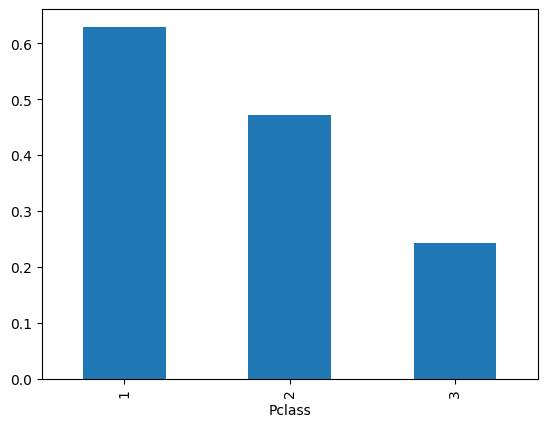

In [7]:
train_data_cleaned.groupby("Pclass")['Survived'].mean().plot(kind='bar')

This shows more than > 60% of survived passengers were travelling in Class 1, around 45% were from Class 2 and only 25% were in Class 3 

<Axes: xlabel='Sex'>

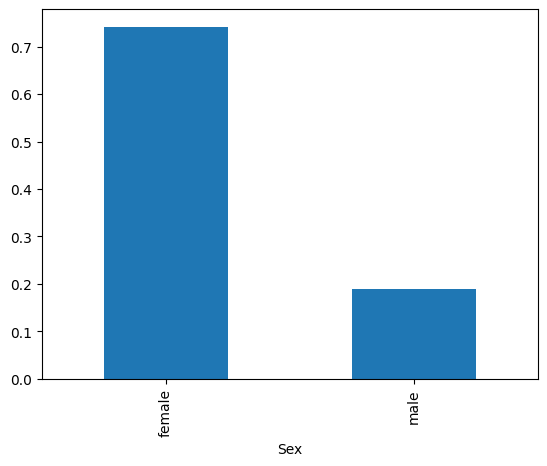

In [8]:
train_data_cleaned.groupby("Sex")['Survived'].mean().plot(kind='bar')

This shows more than > 70% of survived passengers were female and only 20% were male 

<Axes: xlabel='SibSp'>

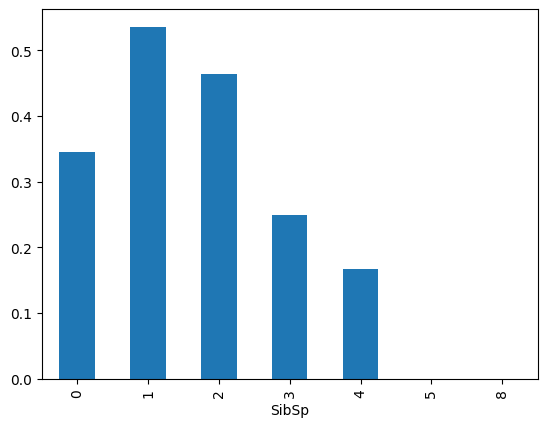

In [9]:
train_data_cleaned.groupby("SibSp")['Survived'].mean().plot(kind='bar')

Passengers having 1-2 of siblings/spouses in the Titanic had larger survival rate	

<Axes: xlabel='Parch'>

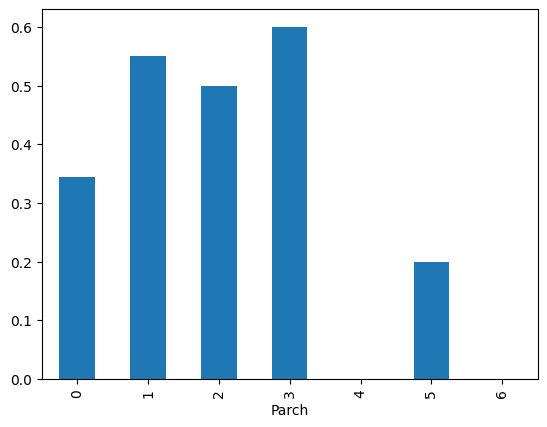

In [10]:
train_data_cleaned.groupby("Parch")['Survived'].mean().plot(kind='bar')

Passengers having 1-3 of parents/children in the Titanic had larger survival rate	

<Axes: xlabel='Embarked'>

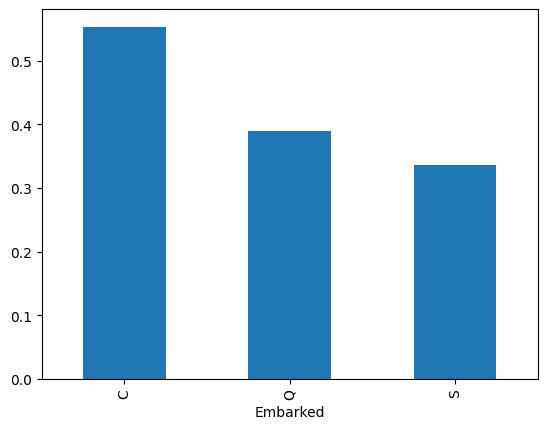

In [13]:
train_data_cleaned.groupby("Embarked")['Survived'].mean().plot(kind='bar')

Most survived passengers embarked in Cherbourg, followed by Queenstown and Southmapton

0       NaN
1       C85
2       NaN
3      C123
4       NaN
       ... 
886     NaN
887     B42
888     NaN
889    C148
890     NaN
Name: Cabin, Length: 891, dtype: object


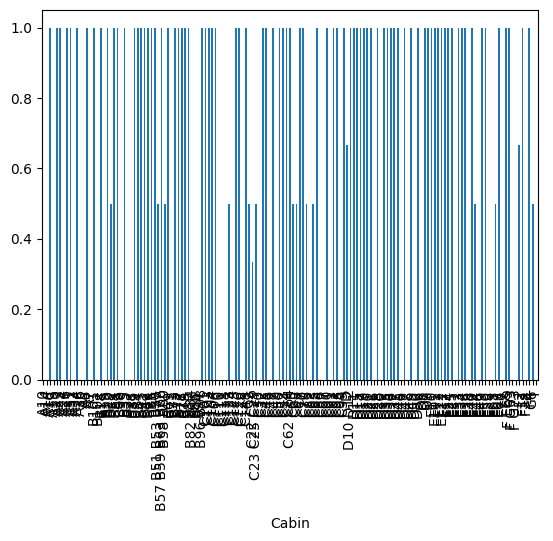

In [16]:
train_data_cleaned.groupby("Cabin")['Survived'].mean().plot(kind='bar')
print(train_data_cleaned["Cabin"])

This does not give any useful information; so we extract the Cabin Category "B", "C" etc. and investigate the dependency

<Axes: xlabel='CabinCategory'>

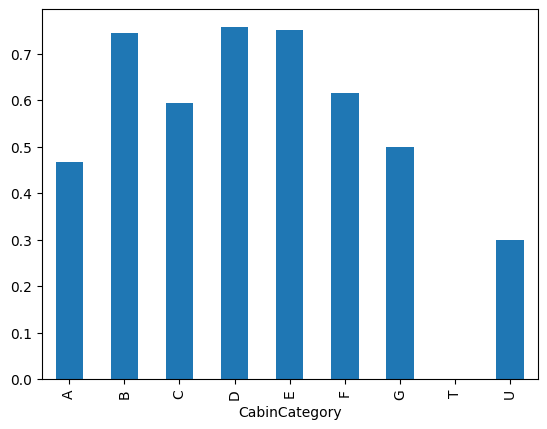

In [17]:
train_data_cleaned['CabinCategory'] = train_data_cleaned['Cabin'].fillna('U1').str[0]
train_data_cleaned.groupby('CabinCategory')['Survived'].mean().plot(kind='bar')

This shows the passengers in Cabins "B", "D" and "E" had highest survival rate

0             A/5 21171
1              PC 17599
2      STON/O2. 3101282
3                113803
4                373450
             ...       
886              211536
887              112053
888          W./C. 6607
889              111369
890              370376
Name: Ticket, Length: 891, dtype: object


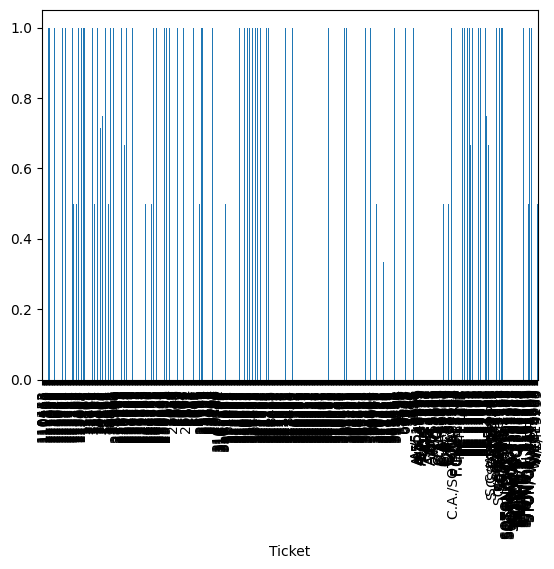

In [19]:
train_data_cleaned.groupby("Ticket")['Survived'].mean().plot(kind='bar')
print(train_data_cleaned["Ticket"])

This is not usefull; So let us investigate the dependencies on the sum of the ticket numbers

<Axes: xlabel='TicketSum', ylabel='Count'>

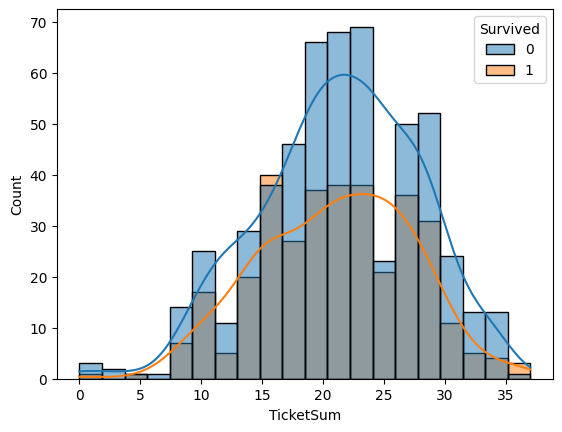

In [24]:
train_data_cleaned['TicketSum'] = train_data_cleaned['Ticket'].apply(sum_ticket)
sns.histplot(data=train_data_cleaned, x='TicketSum', hue='Survived', kde=True)

For Ticket Sum values 15-24 both survived and not survived peaks


Now I shall choose the "float64 features" such as: "Age", "Fare"

<Axes: xlabel='Age', ylabel='Count'>

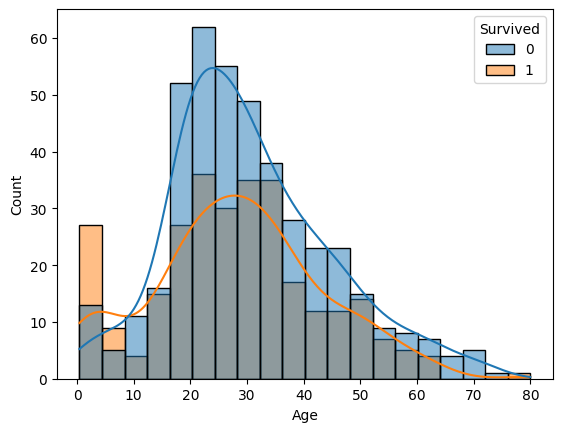

In [25]:
sns.histplot(data=train_data_cleaned, x='Age', hue='Survived', kde=True)

Here also passangers aged 15-35 had both greater survival and greater non survival rates

<Axes: xlabel='Fare', ylabel='Count'>

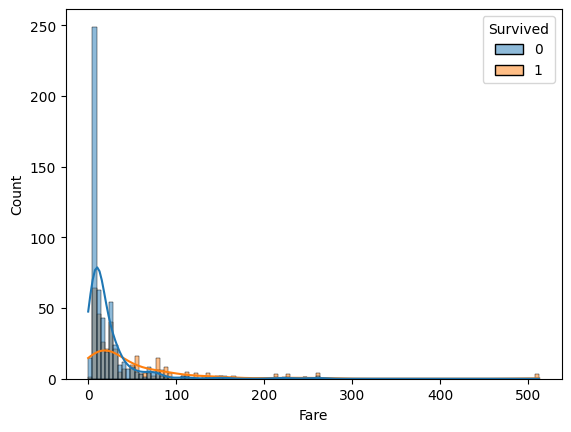

In [26]:
sns.histplot(data=train_data_cleaned, x='Fare', hue='Survived', kde=True)

This shows both survival and non survival rates peaks at low fare values

Finally let me check the correlation of the survival rate with the numerical features

<Axes: >

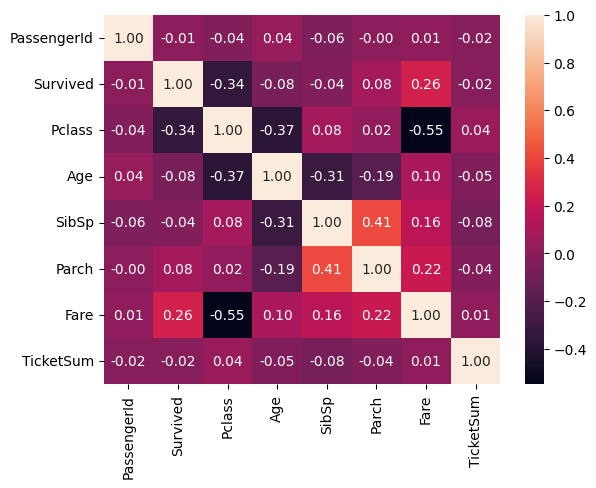

In [32]:
sns.heatmap(train_data_cleaned.corr(numeric_only=True), annot=True, fmt='.2f')

Therefore survival seems to have large correlations with "Fare" and "Pclass"

But this only shows correlation with numerical features; We have also seen strong dependencies of "Survived" with "Sex", "SibSp", "Embarked" and comparatively milder dependencies with "Parch", "Cabin Category" etc.

Therefore we use all the features for training our model and also engineered some new features (see /src/data_preprocessing.py)